In [ ]:
import os
import glob
import xml.etree.ElementTree as ET
from PIL import Image
from torchvision import transforms, models
from torch.utils.data import Dataset, DataLoader
import torch
import torch.nn as nn
import torch.optim as optim
from collections import Counter


# Paths
base_dir = os.path.expanduser(
    "~/.cache/kagglehub/datasets/andrewmvd/face-mask-detection/versions/1/")
train_image_dir = os.path.join(base_dir, "train")
valid_image_dir = os.path.join(base_dir, "valid")
annotation_dir = os.path.join(base_dir, "annotations")

# Classes mapping
label_map = {"with_mask": 0, "without_mask": 1, "mask_weared_incorrect": 2}

# Step 1: Parse Annotations


def parse_annotations(image_dir, annotation_dir):
    label_counts = Counter()
    data = []
    for xml_file in glob.glob(os.path.join(annotation_dir, "*.xml")):
        tree = ET.parse(xml_file)
        root = tree.getroot()

        filename = root.find("filename").text
        img_path = os.path.join(image_dir, filename)

        # Skip missing images
        if not os.path.exists(img_path):
            print(f"Warning: {img_path} not found. Skipping.")
            continue

        # Assign the most frequent label in the annotation to the entire image
        labels = [obj.find("name").text for obj in root.findall(
            "object") if obj.find("name").text in label_map]
        if labels:
            most_common_label = Counter(labels).most_common(1)[0][0]
            label_counts[most_common_label] += 1
            data.append((img_path, label_map[most_common_label]))
    print("Label distribution:", dict(label_counts))
    return data


# Parse training and validation data
train_data = parse_annotations(train_image_dir, annotation_dir)
valid_data = parse_annotations(valid_image_dir, annotation_dir)

print(f"Training samples: {len(train_data)}")
print(f"Validation samples: {len(valid_data)}")

# Step 2: Define Dataset Class


class MaskDataset(Dataset):
    def __init__(self, data, transform=None):
        self.data = data
        self.transform = transform

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        img_path, label = self.data[idx]
        try:
            image = Image.open(img_path).convert("RGB")
            if self.transform:
                image = self.transform(image)
            return image, label
        except Exception as e:
            print(f"Error loading image {img_path}: {e}")
            # Retry with another sample
            return self.__getitem__((idx + 1) % len(self.data))


# Step 3: Define Transforms
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

# Create datasets and dataloaders
train_dataset = MaskDataset(train_data, transform=transform)
valid_dataset = MaskDataset(valid_data, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=32,
                          shuffle=True, num_workers=4)
valid_loader = DataLoader(valid_dataset, batch_size=32,
                          shuffle=False, num_workers=4)

# Step 4: Define Model
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = models.resnet18(pretrained=True)
model.fc = nn.Linear(model.fc.in_features, len(
    label_map))  # Output layer for 3 classes
model = model.to(device)

# Step 5: Loss Function and Optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

# Step 6: Train the Model
num_epochs = 10
for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    print(
        f"Epoch {epoch+1}/{num_epochs}, Loss: {running_loss/len(train_loader)}")

# Step 7: Validate the Model
model.eval()
correct = 0
total = 0
with torch.no_grad():
    for images, labels in valid_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

print(f"Validation Accuracy: {100 * correct / total}%")

# Save the model
torch.save(model.state_dict(), "mask_detector_model.pth")
print("Model saved as mask_detector_model.pth")


/home/pedro/Codes/computational-vision/.venv/lib/python3.12/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/home/pedro/Codes/computational-vision/.venv/lib/python3.12/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
/tmp/ipykernel_276778/1877917987.py:17: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.c

Predicted class: with_mask


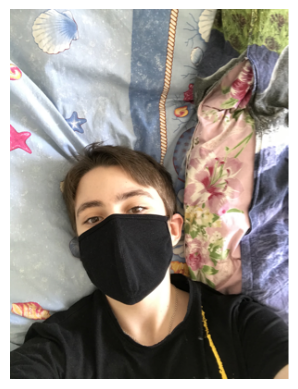

Predicted class: without_mask


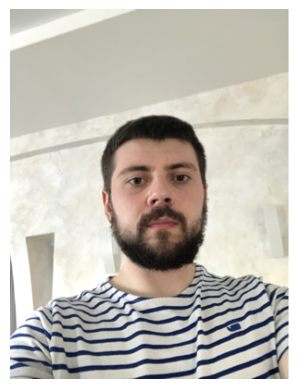

Predicted class: mask_weared_incorrect


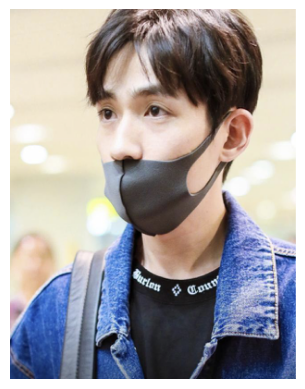

In [ ]:
import matplotlib.pyplot as plt
import os
import glob
import xml.etree.ElementTree as ET
from PIL import Image
from torchvision import transforms, models
from torch.utils.data import Dataset, DataLoader
import torch
import torch.nn as nn
import torch.optim as optim
from collections import Counter


model = models.resnet18(pretrained=True)

model.fc = nn.Linear(model.fc.in_features, 3)
model.load_state_dict(torch.load("mask_detector_model.pth"))
model.eval()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

label_map = {"with_mask": 0, "without_mask": 1, "mask_weared_incorrect": 2}

for image_path in ["./maksssksksss4.png", "./maksssksksss51.png", "./maksssksksss832.png"]:

    image = Image.open(image_path).convert("RGB")
    image = transform(image).unsqueeze(0).to(device)

    model.eval()
    with torch.no_grad():
        output = model(image)
        _, predicted = torch.max(output, 1)
        print(f"Predicted class: {list(label_map.keys())[predicted.item()]}")

    plt.imshow(Image.open(image_path))
    plt.axis("off")
    plt.show()


/tmp/ipykernel_276778/3707123364.py:29: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(


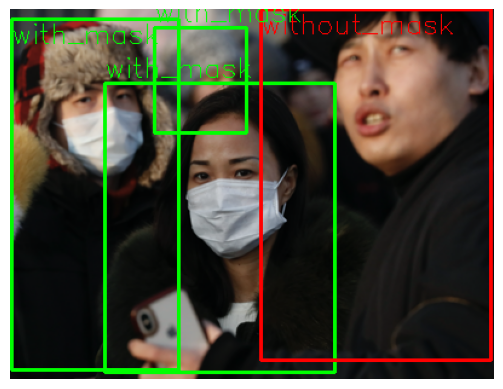

In [14]:
import os
import cv2
import torch
import torchvision.transforms as transforms
from torchvision import models
from torchvision.models.detection import fasterrcnn_resnet50_fpn
from PIL import Image
import torch.nn as nn


# Classes mapping
label_map = {"with_mask": 0, "without_mask": 1, "mask_weared_incorrect": 2}
reverse_label_map = {v: k for k, v in label_map.items()}
color_map = {
    "with_mask": (0, 255, 0),  # Green
    "without_mask": (0, 0, 255),  # Red
    "mask_weared_incorrect": (255, 255, 0)  # Yellow
}

# Load Pretrained Object Detection Model (Faster R-CNN)
object_detector = fasterrcnn_resnet50_fpn(pretrained=True)
object_detector.eval()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
object_detector.to(device)

# Load Mask Classification Model
model = models.resnet18(pretrained=True)
model.fc = nn.Linear(model.fc.in_features, len(label_map))
model.load_state_dict(torch.load(
    "mask_detector_model.pth", map_location=device))
model = model.to(device)
model.eval()

# Define Transforms
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])


def clamp(val, min_val, max_val):
    """Clamp a value between min_val and max_val."""
    return max(min(val, max_val), min_val)


def detect_and_classify(image_path):
    # Load Image
    image = cv2.imread(image_path)
    orig_image = image.copy()
    h, w, _ = image.shape
    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    image_tensor = transforms.ToTensor()(image_rgb).unsqueeze(0).to(device)

    # Detect People in Image
    with torch.no_grad():
        detections = object_detector(image_tensor)[0]

    # Process Detections
    for i, (box, score, label) in enumerate(zip(detections['boxes'], detections['scores'], detections['labels'])):
        # Keep only people (label 1 in COCO dataset)
        if score < 0.8 or label != 1:
            continue

        # Extract and clamp bounding box
        x1, y1, x2, y2 = map(int, box.tolist())
        x1, y1 = clamp(x1, 0, w), clamp(y1, 0, h)
        x2, y2 = clamp(x2, 0, w), clamp(y2, 0, h)

        # Crop and classify each detected region
        person_crop = orig_image[y1:y2, x1:x2]
        try:
            person_image = Image.fromarray(
                cv2.cvtColor(person_crop, cv2.COLOR_BGR2RGB))
            person_image = transform(person_image).unsqueeze(0).to(device)

            with torch.no_grad():
                outputs = model(person_image)
                _, predicted = torch.max(outputs, 1)
                class_label = reverse_label_map[predicted.item()]

            # Draw Bounding Box and Label
            color = color_map[class_label]
            cv2.rectangle(orig_image, (x1, y1), (x2, y2), color, 2)

            # Adjust label position (place below the box if it overflows)
            text_y = y1 - 5 if y1 - 10 > 0 else y1 + 20
            cv2.putText(orig_image, class_label, (x1, text_y),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.75, color, 1)
        except Exception as e:
            print(f"Error processing region: {e}")

    # Display the Image with Annotations
    plt.imshow(cv2.cvtColor(orig_image, cv2.COLOR_BGR2RGB))
    plt.axis("off")
    plt.show()


# Test the function
test_image_path = "./maksssksksss83.png"
detect_and_classify(test_image_path)
